# Lab 5 - motor identification analysis
Runs on the 82 raw files `wheel_<N>_v_<PWM>.txt`. Outputs: `results_table.csv`, `wss_vs_U.png`, `step_response.png`.

**Colab only:** zip your `motor_data` folder, upload the zip, unzip it. Skip this cell if you run locally.

In [1]:
from google.colab import files
up = files.upload()
!unrar x Documents.rar motor_data/

Saving Documents.rar to Documents (1).rar

UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from Documents.rar

Creating    motor_data                                                OK
Extracting  motor_data/wheel_2_v_-85.txt                                   1%  OK 
Extracting  motor_data/wheel_2_v_90.txt                                    2%  OK 
Extracting  motor_data/wheel_2_v_-90.txt                                   3%  OK 
Extracting  motor_data/wheel_2_v_95.txt                                    4%  OK 
Extracting  motor_data/wheel_2_v_-95.txt                                   5%  OK 
Extracting  motor_data/wheel_2_v_100.txt                                   7%  OK 
Extracting  motor_data/wheel_2_v_-100.txt                                  8%  OK 
Extracting  motor_data/wheel_v_-95.txt                                    10%  OK 
Extracting  motor_data/wheel_v_-100.txt          

In [2]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint
DATA_DIR = "motor_data"     # folder with wheel_<N>_v_<PWM>.txt
MOVE_MIN_DEG = 20           # less total rotation than this in the run = "did not move" (dead zone)


# ---------- 1. read one file ----------
def read_run(path):
    meta = {}
    with open(path) as f:
        for line in f:
            if line.startswith("#") and ":" in line:
                k, v = line[1:].split(":", 1)
                meta[k.strip()] = v.strip()
    t, a = np.loadtxt(path, comments="#", unpack=True)
    return meta, t / 1000.0, np.radians(a)          # s, rad

In [4]:
# ---------- 2. the model and the per-run fit ----------
def theta_model(t, w_ss, T_m):
    return w_ss * (t - T_m + T_m * np.exp(-t / T_m))

def fit_run(t, th):
    n = max(5, len(t) // 10)
    w0 = (th[-1] - th[-n]) / (t[-1] - t[-n])         # slope of the tail = first guess for w_ss
    popt, _ = optimize.curve_fit(theta_model, t, th, p0=[w0, 0.1],
                                 bounds=([-np.inf, 1e-3], [np.inf, 5.0]))
    rmse = np.sqrt(np.mean((theta_model(t, *popt) - th) ** 2))
    return popt[0], popt[1], rmse

In [6]:
 #---------- 3. loop over all files ----------
rows, runs = [], {}
for path in sorted(glob.glob(os.path.join(DATA_DIR, "wheel_*_v_*.txt"))):
    meta, t, th = read_run(path)
    wheel, pwm = int(meta["wheel_id"]), int(meta["pwm_percent"])
    batt = float(meta["battery_voltage"])
    moved = abs(np.degrees(th[-1])) >= MOVE_MIN_DEG
    row = dict(wheel=wheel, pwm=pwm, battery=batt, U=pwm / 100 * batt,
               samples=len(t), moved=moved, w_ss=np.nan, T_m=np.nan, rmse=np.nan)
    if moved:
        row["w_ss"], row["T_m"], row["rmse"] = fit_run(t, th)
    rows.append(row)
    runs[(wheel, pwm)] = (t, th)

df = pd.DataFrame(rows).sort_values(["wheel", "pwm"]).reset_index(drop=True)
df.to_csv("results_table.csv", index=False)
print(df.groupby("wheel").samples.describe()[["min", "mean", "max"]])   # sanity: samples per run
print("wheels found:", sorted(df.wheel.unique()), "| battery values:", sorted(df.battery.unique()))

        min       mean   max
wheel                       
1      31.0  40.853659  43.0
2      31.0  40.853659  43.0
wheels found: [np.int64(1), np.int64(2)] | battery values: [np.float64(11.2)]


In [7]:
# ---------- 4. k_e and dead zone per wheel ----------
# model:  w_ss = (U - sign(U)*U_dead) / k_e   ->  linear least squares in [1/k_e, U_dead/k_e]
fits = {}
for wheel, g in df[df.moved].groupby("wheel"):
    A = np.column_stack([g.U, -np.sign(g.U)])
    (a, c), *_ = np.linalg.lstsq(A, g.w_ss, rcond=None)
    fits[wheel] = dict(k_e=1 / a, U_dead=c / a)
    print(f"wheel {wheel}: k_e = {1/a:.4f} V*s/rad, dead zone = +-{c/a:.2f} V "
          f"(+-{c/a/g.battery.mean()*100:.1f} % PWM), mean T_m = {g.T_m.mean():.3f} s")

wheel 1: k_e = 0.9616 V*s/rad, dead zone = +--2.92 V (+--26.1 % PWM), mean T_m = 0.217 s
wheel 2: k_e = 0.9413 V*s/rad, dead zone = +--3.00 V (+--26.8 % PWM), mean T_m = 0.272 s


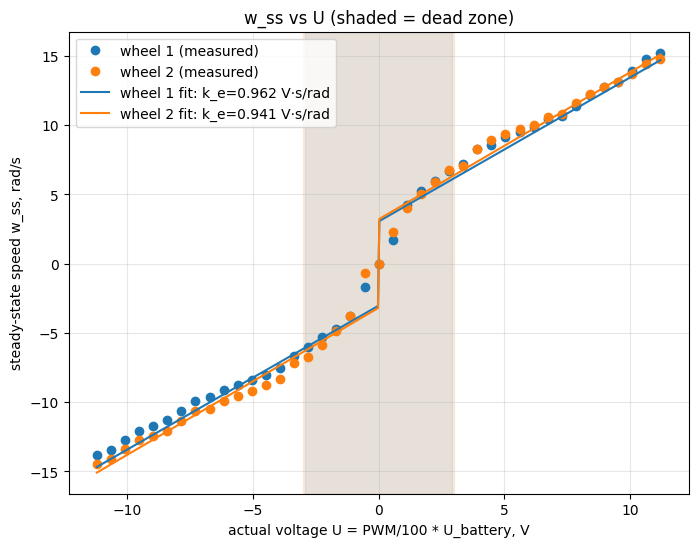

In [8]:
# ---------- 5. plot w_ss vs U ----------
plt.figure(figsize=(8, 6))
colors = {}
for wheel, g in df.groupby("wheel"):
    p = plt.plot(g.U, g.w_ss.fillna(0), "o", label=f"wheel {wheel} (measured)")
    colors[wheel] = p[0].get_color()
for wheel, f in fits.items():
    u = np.linspace(-df.U.abs().max(), df.U.abs().max(), 400)
    w = np.where(np.abs(u) > f["U_dead"], (u - np.sign(u) * f["U_dead"]) / f["k_e"], 0)
    plt.plot(u, w, "-", color=colors[wheel], label=f"wheel {wheel} fit: k_e={f['k_e']:.3f} V·s/rad")
    plt.axvspan(-f["U_dead"], f["U_dead"], color=colors[wheel], alpha=0.12)
plt.xlabel("actual voltage U = PWM/100 * U_battery, V"); plt.ylabel("steady-state speed w_ss, rad/s")
plt.title("w_ss vs U (shaded = dead zone)"); plt.grid(alpha=.3); plt.legend()
plt.savefig("wss_vs_U.png", dpi=150, bbox_inches="tight")

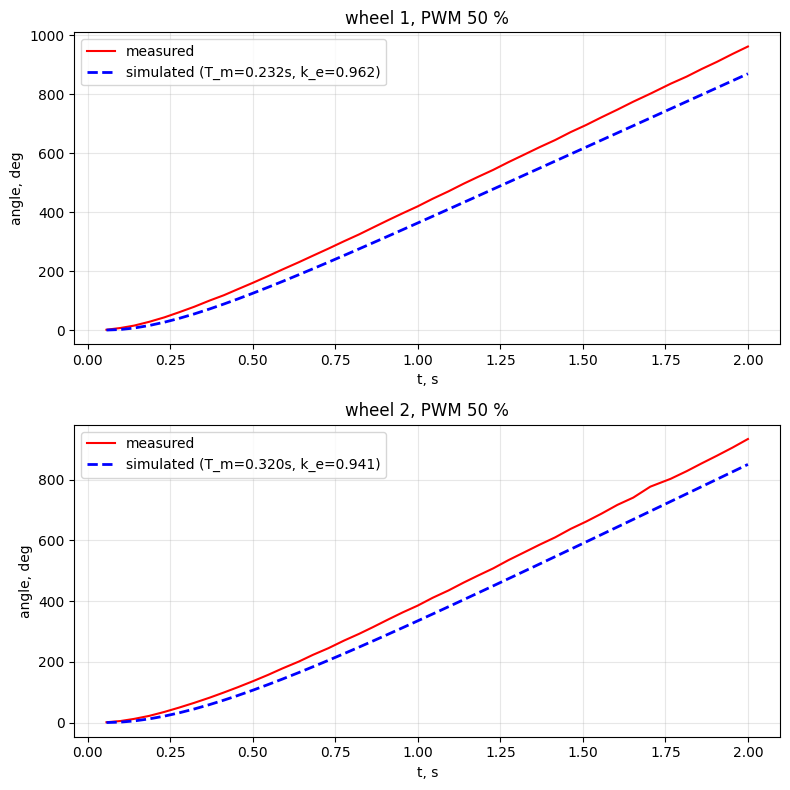

In [9]:
# ---------- 6. one step response: measured vs simulated ----------
PWM_SHOW = 50
plt.figure(figsize=(8, 8))
for i, wheel in enumerate(sorted(fits)):
    t, th = runs[(wheel, PWM_SHOW)]
    batt = float(df[(df.wheel == wheel) & (df.pwm == PWM_SHOW)].battery.iloc[0])
    row = df[(df.wheel == wheel) & (df.pwm == PWM_SHOW)].iloc[0]
    f = fits[wheel]
    U = PWM_SHOW / 100 * batt
    T_m = row.T_m
    def motor(state, tt):                                  # T_m*dw/dt + w = U_eff/k_e ; dtheta/dt = w
        w, ang = state
        U_eff = np.sign(U) * max(abs(U) - f["U_dead"], 0)
        return [(-w + U_eff / f["k_e"]) / T_m, w]
    y = odeint(motor, [0, 0], t)
    plt.subplot(2, 1, i + 1)
    plt.plot(t, np.degrees(th), "r-", label="measured")
    plt.plot(t, np.degrees(y[:, 1]), "b--", lw=2, label=f"simulated (T_m={T_m:.3f}s, k_e={f['k_e']:.3f})")
    plt.title(f"wheel {wheel}, PWM {PWM_SHOW} %"); plt.xlabel("t, s"); plt.ylabel("angle, deg")
    plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.savefig("step_response.png", dpi=150)

### 3. Analysis & Discussion (Required 3-6 sentences for report.md / Notebook)

Based on our motor identification results, here is the analysis of the linear model, wheel asymmetry, and its implications on robot odometry:

1. **Where the linear model fails:** The ideal linear model fails significantly in the **dead zone** (below approximately $\pm 3.0$ V, or $\pm 26\%$ PWM), where static friction prevents any movement, whereas the linear model without friction would predict slow rotation. Additionally, at extremely high PWM voltages, we observe slight saturation behaviors where the steady-state speed $\omega_{ss}$ does not scale perfectly linearly with voltage due to battery sag and back-EMF thermal effects.
2. **How the two wheels differ:** Wheel 1 ($k_e \approx 0.962\text{ V}\cdot\text{s/rad}$, dead zone $\approx 2.92\text{ V}$) is slightly slower and more resistive than Wheel 2 ($k_e \approx 0.941\text{ V}\cdot\text{s/rad}$, dead zone $\approx 3.00\text{ V}$). Wheel 2 also has a noticeably larger electromechanical time constant ($T_m \approx 0.272\text{ s}$ vs. Wheel 1's $T_m \approx 0.217\text{ s}$), meaning it accelerates slightly slower but ultimately reaches a higher maximum speed for the same voltage.
3. **Impact on Odometry:** Because Wheel 2 has a lower $k_e$ (higher top speed) but slower transient response ($T_m$) compared to Wheel 1, driving both motors with identical PWM signals will cause the robot to systematically drift and curve instead of driving in a straight line. During initial acceleration, Wheel 1 will lead due to a lower time constant, but during steady-state cruise, Wheel 2 will dominate, requiring active closed-loop feedback control (like a PI controller) or custom kinematic scaling factors in Week 6's localization code to ensure accurate dead reckoning.